In [1]:
import numpy as np
import pyworld as pw

import torch
import torchaudio

from pitchflower.synthesizer import PitchFlowerSynthesizer

from vocos import Vocos

import IPython.display as ipd

import matplotlib.pyplot as plt

/data/anasynth_nonbp/dtorres/conda_envs/pf_open_inf_2/lib/python3.10/site-packages/pyworld/__init__.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cpu')

Load PitchFlower checkpoint and Vocos

In [ ]:
## In case it gets there is an error during download
# from huggingface_hub.utils import disable_progress_bars
# disable_progress_bars()

In [5]:
synth = PitchFlowerSynthesizer.from_pretrained('diegotg343/PitchFlower').to(device)
vocos = Vocos.from_pretrained("charactr/vocos-mel-24khz").to(device)

Define function to compute the F0 with WORLD

In [38]:
def get_f0(audios):
    _f0, t = pw.harvest(audios.astype(np.float64), fs=24000, frame_period=32/3, f0_floor=20)
    post_f0 = pw.stonemask(audios.astype(np.float64), _f0, t, fs=24000)
    return post_f0

Load sample audio from LibriTTS/dev-clean

In [56]:
og_wav, _ = torchaudio.load('data/2710.wav')
og_wav = og_wav[:36096*3]

Compute original F0 with WORLD

In [57]:
f0 = get_f0(og_wav[0].numpy())
log_f0 = np.where(f0==0, 0, np.log2(f0))
log_f0 = torch.tensor(log_f0, dtype=torch.float32)

/tmp/ipykernel_2369751/3609468626.py:2: RuntimeWarning: divide by zero encountered in log2
  log_f0 = np.where(f0==0, 0, np.log2(f0))


Compute target F0

In [58]:
target_shift = -6/12 
target_f0 = f0*2**(target_shift)
target_log_f0 = log_f0+target_shift

Encode audio with the autoencoder

In [67]:
codes = synth.analyze_audios(og_wav.to(device))

Perform reconstruction with the target F0

In [68]:
rec = synth.synthesize_mels(codes, target_log_f0.unsqueeze(0).to(device))
rec = vocos.decode(rec)

In [70]:
print('Og audio')
display(ipd.Audio(og_wav.cpu().numpy(), rate=24000))

print('Reconstructed audio')
display(ipd.Audio(rec.cpu()[0].numpy(), rate=24000))

Og audio


Reconstructed audio


Alternatively, perform shifting in one function call

In [71]:
flow_mels = synth.reconstruct_mels(og_wav.to(device), target_log_f0.unsqueeze(0).to(device), steps=10, w=3.0)
flow_audios = vocos.decode(flow_mels)

In [72]:
print('Reconstructed audio')
display(ipd.Audio(flow_audios.cpu()[0].numpy(), rate=24000))

Reconstructed audio


Compute resulting F0

In [74]:
flow_f0 = get_f0(flow_audios[0].numpy(force=True))

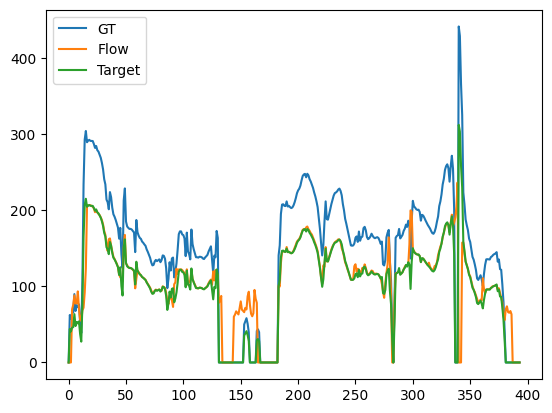

In [75]:
plt.plot(f0, label='GT')
plt.plot(flow_f0, label='Flow')
plt.plot(target_f0, label='Target')
plt.legend()